# 23 · Original MNIST with finite image observables

Use all ten digits at their native 28 × 28 resolution. Every gallery contains two images of each digit. The benchmark scores transformed source retrieval and source-excluded same-digit retrieval as separate tasks.

On transformed MNIST queries, aligned local Q scores 97.7% for identity and 45.3% for same-digit retrieval. Aligned pixels score 95.9% and 37.5%. Removing the Q orientation phase drops same-digit retrieval to 34.3%.

In [1]:
from pathlib import Path
import sys, json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.open_images import COMPONENTS,Observation,translate,describe,open_moment,similarity_profile
from observables.stage6 import CONDITIONS,SEED,load_data,galleries,view,run,paired_interval
OUT=ROOT/'results'/'stage6'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

## Data and comparison design
Six development galleries are drawn from the official training split and 16 test galleries from the official test split. Each source appears in one gallery within its split. The paired development metric for each endpoint is selected by mean accuracy over eight transformed conditions. There are no trained fusion weights. The uniform profile is a fixed comparison, and all 11 individual observables remain available. Two additional controls compare aligned Q magnitude and aligned gradient strength. The uniform profile uses the original 11 coordinates.

The source candidate is included for identity retrieval, with chance 1/20. For class retrieval it is excluded, leaving one correct same-label candidate among 19, with chance 1/19. Class retrieval asks about a distinct handwriting example even when the query is clean. Clean identity retrieval is an exact-match control, excluded from aggregate transformed results.

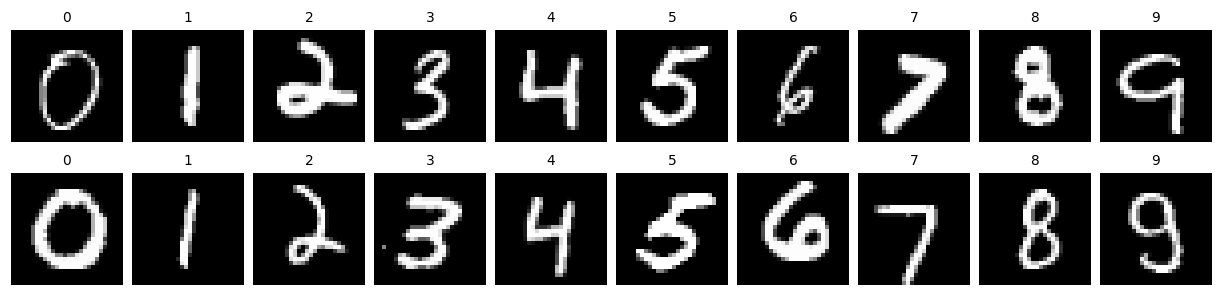

Official test array: (10000, 28, 28) · illustrated gallery: 20 images


In [3]:
data=load_data()
_,_,ids,images,labels=next(g for g in galleries(data) if g[0]=='test')
fig,axes=plt.subplots(2,10,figsize=(11,2.6))
for ax,index in zip(axes.flat,np.argsort(labels,kind='stable').reshape(10,2).T.ravel()):
    ax.imshow(images[index],cmap='gray',vmin=0,vmax=1)
    ax.set_title(f'{labels[index]}',fontsize=9);ax.set_axis_off()
show('23_gallery_example')
print('Official test array:',data['x_test'].shape,'· illustrated gallery:',len(ids),'images')

## Evaluate the frozen protocol
The manifest pins the original MNIST archive by SHA-256. The benchmark saves raw pair distances, selected offsets, coverage, gallery membership, and query-level outcomes. Set RECOMPUTE to True to regenerate the benchmark. The saved experiment includes all 440 source images and 3,960 query views across both splits.

In [5]:
RECOMPUTE=False
files=['manifest.json','decisions.csv.gz','pair_distances.csv.gz','gallery_membership.csv']
if RECOMPUTE or not all((OUT/f).exists() for f in files):
    decisions,_,manifest=run(OUT)
else:
    decisions=pd.read_csv(OUT/'decisions.csv.gz')
    manifest=json.loads((OUT/'manifest.json').read_text())
assert manifest['test_galleries']==16 and manifest['development_galleries']==6
assert len(decisions)==3960*14
print('Development-selected decisions:',manifest['development_selected'])
test=decisions.query("split=='test' and condition!='clean'")
summary=test.groupby('method')[['identity','class']].mean()
display(summary.sort_values('class',ascending=False).round(4))
summary.to_csv(OUT/'transformed_summary.csv')

Development-selected decisions: {'identity': 'aligned local Q', 'class': 'local Q'}


,identity,class
method,,
local Q,0.9012,0.4660
aligned local Q,0.9773,0.4527
aligned pixels,0.9594,0.3750
aligned Q magnitude,0.9633,0.3434
pixels,0.7590,0.3031
uniform profile,0.9234,0.3031
HOG,0.7844,0.2902
aligned gradient strength,0.7102,0.2164
DCT power,0.6492,0.1680


## Compare the same registration policy for both fields
The plotted methods include the fixed and registered versions of pixels and Q, plus the gradient histogram and uniform profile. Bootstrap intervals resample the 16 entire test galleries. This preserves shared distractors, all source views, and paired decisions. The intervals condition on this balanced gallery design.

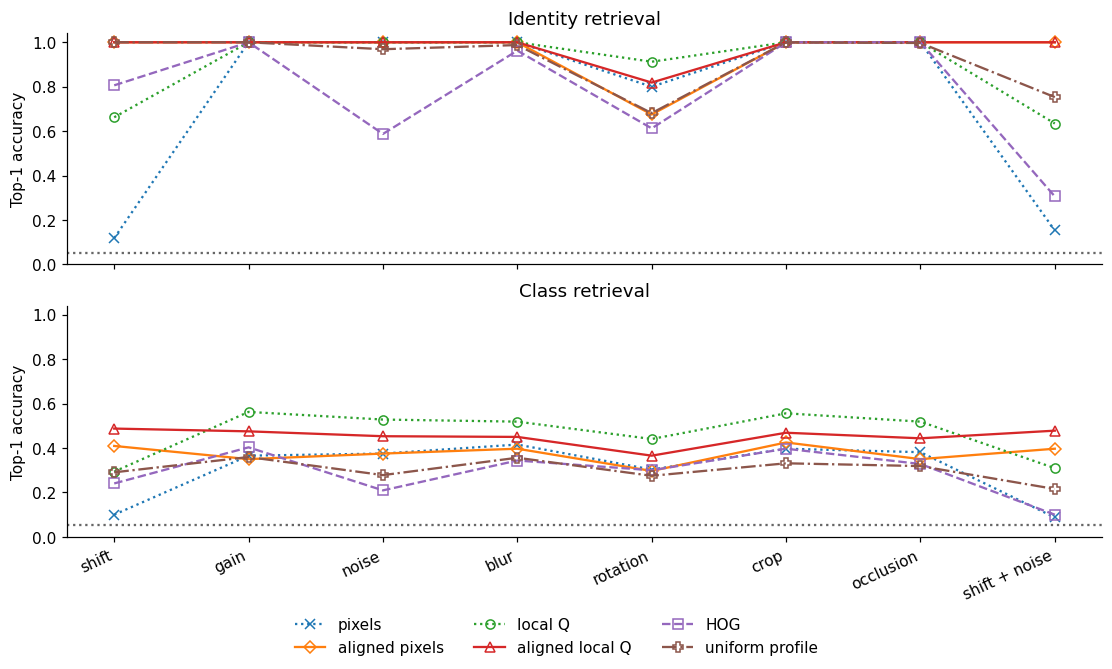

,endpoint,left,right,difference,low95,high95
0,identity,aligned pixels,pixels,0.2004,0.1910,0.2086
1,identity,aligned local Q,local Q,0.0762,0.0676,0.0848
2,identity,aligned local Q,aligned pixels,0.0180,0.0125,0.0238
3,identity,aligned local Q,aligned Q magnitude,0.0141,0.0070,0.0211
4,identity,aligned local Q,aligned gradient strength,0.2672,0.2590,0.2758
5,class,aligned pixels,pixels,0.0719,0.0437,0.1012
6,class,aligned local Q,local Q,-0.0133,-0.0379,0.0156
7,class,aligned local Q,aligned pixels,0.0777,0.0441,0.1113
8,class,aligned local Q,aligned Q magnitude,0.1094,0.0676,0.1484
9,class,aligned local Q,aligned gradient strength,0.2363,0.2023,0.2707


In [7]:
selected=['pixels','aligned pixels','local Q','aligned local Q','HOG','uniform profile']
styles=['x:','D-','o:','^-','s--','P-.']
fig,axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
for ax,endpoint,chance in zip(axes,['identity','class'],[1/20,1/19]):
    by=test.groupby(['condition','method'])[endpoint].mean().unstack().loc[list(CONDITIONS)[1:]]
    for method,style in zip(selected,styles):
        ax.plot(range(len(by)),by[method],style,label=method,markerfacecolor='none')
    ax.axhline(chance,color='.4',ls=':')
    ax.set(ylabel='Top-1 accuracy',title=f'{endpoint.capitalize()} retrieval',ylim=(0,1.04))
axes[-1].set_xticks(range(len(by)),by.index,rotation=25,ha='right')
fig.legend(*axes[0].get_legend_handles_labels(),loc='outside lower center',ncol=3,frameon=False)
show('23_mnist_retrieval')
rows=[]
for endpoint in ['identity','class']:
    for a,b in [('aligned pixels','pixels'),('aligned local Q','local Q'),
                ('aligned local Q','aligned pixels'),('aligned local Q','aligned Q magnitude'),
                ('aligned local Q','aligned gradient strength')]:
        rows.append((endpoint,a,b,*paired_interval(test,a,b,endpoint)))
contrasts=pd.DataFrame(rows,columns=['endpoint','left','right','difference','low95','high95'])
display(contrasts.round(4))
contrasts.to_csv(OUT/'paired_differences.csv',index=False)

## Read the endpoint before drawing a conclusion
Registration addresses integer translation directly. Other perturbations can change the relative value of the field, even under an identical search. Same-label retrieval depends on a different writing sample and should be interpreted against that gallery design. The study does not estimate standard 10-class classifier accuracy.

## Why the polar component has weak signal
Magnitude weighting makes the first angular moment the sum of the finite gradients divided by total gradient magnitude. On a fully observed row the sum of the finite differences depends only on the first two and last two intensities. When the digit is surrounded by black margin, these terms can all vanish despite strong internal strokes. The same argument applies vertically. Measure this cancellation on the held-out originals.

In [9]:
from observables.open_images import finite_gradient
polar=[]
for split,block,ids,images,labels in galleries(data):
    if split=='test':
        for source,image in zip(ids,images):
            gradient=finite_gradient(image,np.ones(image.shape,dtype=bool))
            polar.append((source,abs(gradient.sum())/np.abs(gradient).sum()))
polar=pd.DataFrame(polar,columns=['source','polar_magnitude'])
print(f'Numerically zero polar moment: {(polar.polar_magnitude<1e-12).sum()} of {len(polar)} clean test originals')
polar.to_csv(OUT/'clean_polar_magnitude.csv',index=False)

Numerically zero polar moment: 281 of 320 clean test originals
